# 07 - Machine Learning Models

**Models compared**

* Linear regression (median imputation + standardisation) - interpretable linear benchmark.
* Random forest - non-linear, robust, but slower and less accurate than boosting on tabular data.
* XGBoost - gradient-boosted trees, the expected production model.

All models share the same feature matrix, the same rolling-origin folds and the same 48-day direct forecasting protocol.

In [1]:
import sys, json
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110
print("Project root:", PROJECT_ROOT)

Project root: rossmann-sales-forecasting


In [2]:
results = json.loads((PROJECT_ROOT / "outputs" / "metrics" / "validation_results.json").read_text())
rows = []
for fold, payload in results["folds"].items():
    for model, metrics in payload["models"].items():
        rows.append({"fold": fold, "model": model, "rmspe": metrics["rmspe"], "mae": metrics["mae"],
                     "wape": metrics["wape"], "fit_seconds": metrics.get("fit_seconds")})
frame = pd.DataFrame(rows)

pivot = frame.pivot(index="model", columns="fold", values="rmspe").round(4)
display(pivot)
display(pd.DataFrame(results["summary"]).round(4))

fold,fold_1,fold_2,fold_3,holdout
model,,,,
ensemble_xgb_hist,0.2303,0.1772,0.1553,0.1381
historical_average,0.2625,0.2616,0.2189,0.2283
linear_regression,0.3500,0.2716,0.2380,0.2209
random_forest,0.2827,0.2041,0.1742,0.1700
seasonal_naive,0.3966,0.3502,0.4967,0.2304
xgboost,0.2546,0.1911,0.1744,0.1714


,model,mean_rmspe,std_rmspe,mean_mae,mean_wape
0,ensemble_xgb_hist,0.1752,0.0400,862.7193,0.1217
1,xgboost,0.1979,0.0388,989.2680,0.1395
2,random_forest,0.2078,0.0522,973.5796,0.1374
3,historical_average,0.2428,0.0225,1204.8148,0.1699
4,linear_regression,0.2701,0.0573,1172.1670,0.1655
5,seasonal_naive,0.3685,0.1105,1789.1057,0.2522


## 1. Model comparison

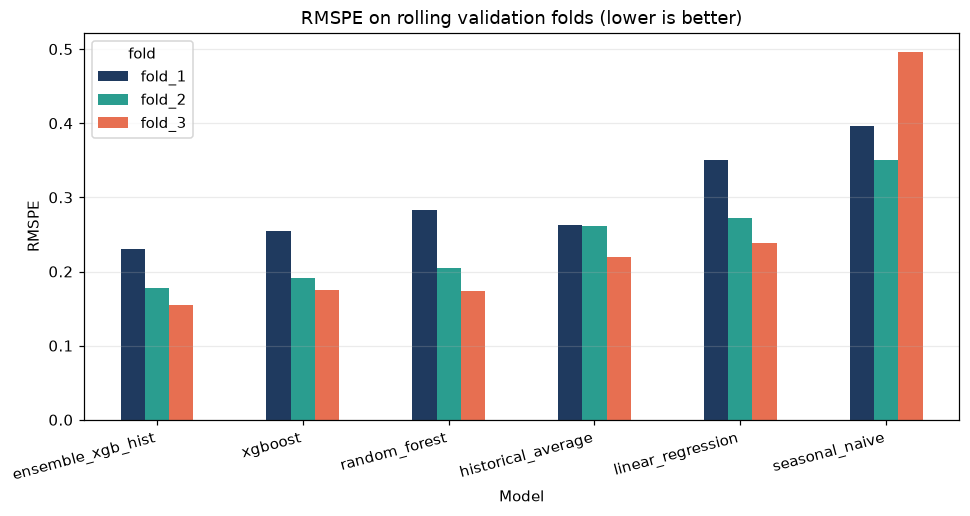

In [3]:
order = frame.groupby("model").rmspe.mean().sort_values().index
fig, ax = plt.subplots(figsize=(9, 4.8))
frame[frame.fold != "holdout"].pivot(index="model", columns="fold", values="rmspe").loc[order].plot(
    kind="bar", ax=ax, color=["#1f3a5f", "#2a9d8f", "#e76f51"])
ax.set_title("RMSPE on rolling validation folds (lower is better)")
ax.set_ylabel("RMSPE")
ax.set_xlabel("Model")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

**Interpretation.** The ranking of single models is consistent across folds: XGBoost is first, the random forest is second, and the linear model is close to (but slightly worse than) the historical average. The selected model is not a single model, however: a 65% XGBoost + 35% historical-average ensemble wins every fold and the holdout. On the single holdout the random forest edges XGBoost by 0.0014 RMSPE - inside seasonal noise - which is exactly why model selection uses the three rolling folds, not one window. The gap between tree ensembles and the linear model is evidence of non-linear interactions (promotion x store type, weekday x season, recent momentum).

In [4]:
holdout = frame[frame.fold == "holdout"].sort_values("rmspe")
display(holdout.round(4))
best = holdout.iloc[0]
print(f"Best holdout model: {best.model} with RMSPE {best.rmspe:.4f}")

,fold,model,rmspe,mae,wape,fit_seconds
23,holdout,ensemble_xgb_hist,0.1381,826.6725,0.1157,0.0
21,holdout,random_forest,0.1700,913.5443,0.1279,168.7
22,holdout,xgboost,0.1714,1008.1900,0.1411,48.2
20,holdout,linear_regression,0.2209,1202.8072,0.1684,6.5
18,holdout,historical_average,0.2283,1259.3611,0.1763,0.3
19,holdout,seasonal_naive,0.2304,1466.6554,0.2053,0.3


Best holdout model: ensemble_xgb_hist with RMSPE 0.1381


## 2. Feature importance

Gain-based importance counts how much a feature improves the trees' objective. It is useful for sanity checking (the store's recent level should matter; the store ID should not), but it is not a causal effect and it is biased towards high-cardinality continuous features.

Model: xgboost


,gain_importance
Promo,0.309478
sales_roll_mean_365,0.098287
sales_roll_mean_90,0.082120
PromoTomorrow,0.072788
sales_lag_1,0.032381
customers_roll_mean_28,0.030165
sales_roll_std_28,0.026667
DayOfWeek,0.023421
IsMonthEnd,0.020196
SinDayOfWeek,0.018742


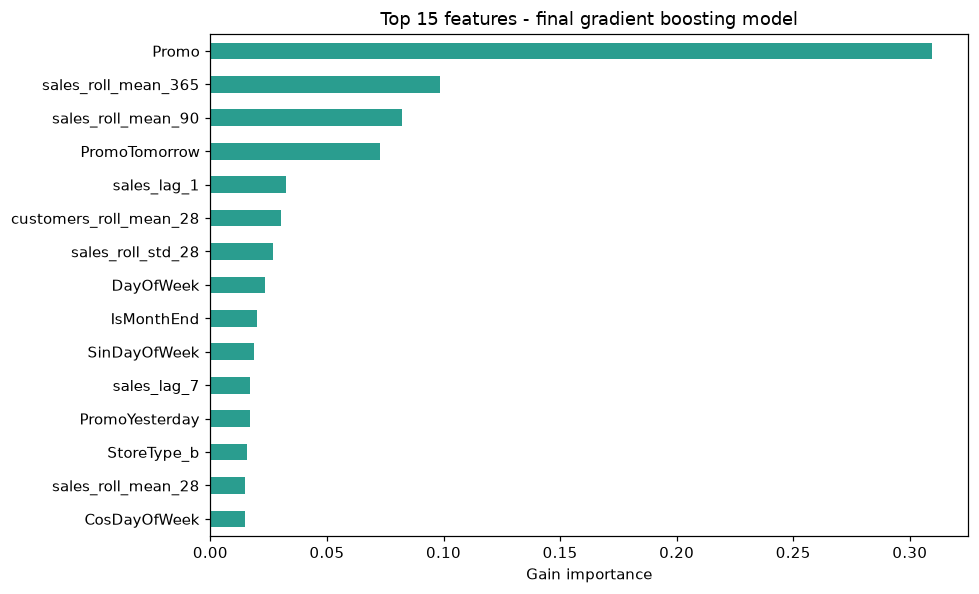

In [5]:
import joblib

model_files = sorted((PROJECT_ROOT / "outputs" / "models").glob("final_*.joblib"))
if model_files:
    artifact = joblib.load(model_files[-1])
    print("Model:", artifact["model_name"])
    model = artifact["model"]
    importance = pd.Series(model.feature_importances_, index=artifact["features"]).sort_values(ascending=False)
    display(importance.head(15).to_frame("gain_importance"))
    fig, ax = plt.subplots(figsize=(9, 5.5))
    importance.head(15).iloc[::-1].plot(kind="barh", ax=ax, color="#2a9d8f")
    ax.set_title("Top 15 features - final gradient boosting model")
    ax.set_xlabel("Gain importance")
    plt.tight_layout()
    plt.show()
else:
    print("Run `python -m src.predict` first to create the final model artefact.")

## 3. Why the boosted trees win here - and why the ensemble wins overall

* **Non-linearity:** promotion effects differ by store type and by baseline level; trees model this without manual interactions.
* **Missing values:** early rows have no 365-day history; XGBoost handles missing values natively, while the linear model needs imputation.
* **Scale:** 800k training rows and 46 features are comfortably within XGBoost's regime.
* **Regularisation:** `max_depth=8`, `min_child_weight=6` and `lambda=2` limit overfitting to individual stores.

The final forecast blends XGBoost with the historical average (65/35). The blend keeps the non-linear signal but anchors the store level, cutting the holdout bias from -10.8% to -7.9% and RMSPE from 0.1714 to 0.1381.

**Why not a neural network?** With 46 tabular features, 1,115 stores and no sequence model, gradient boosting is the stronger and far cheaper baseline. A deep model would be justified only with much more data and a clear sequence structure.

**Why not one model per store?** 1,115 models would each see ~750 observations, many of them zeros, and could not share promotion or seasonality patterns. The global model borrows strength across stores; store-level history enters through the lag/rolling features.